# Simulation and early prediction

Generate events with the mock engine, extract trajectory features and ask how much post-fault observation a classifier needs. The mock engine is a synthetic classical multi-machine model, not the IEEE system; use it for method development, not for findings.

In [1]:
import numpy as np
import pandas as pd
import tranpy
from sklearn.linear_model import LogisticRegression
from tranpy.datasets import FAULT_CLEAR, FAULT_START, detect_fault_timing
from tranpy.early_prediction import find_knee_point, run_early_prediction
from tranpy.plotting import plot_early_prediction
from tranpy.simulation import MockEngine, ScenarioSampler, generate_events
from tranpy_core.models import make_pipeline
from pathlib import Path
import matplotlib.pyplot as plt
from tranpy_core.plotting import publication_style, save_figure

FIGURES = Path("outputs")
plt.rcParams["figure.dpi"] = 150

## Generate events

In [2]:
engine = MockEngine("new_england", simulation_time_s=6.0)
sampler = ScenarioSampler(n_lines=engine.n_lines, n_loads=engine.n_loads, simulation_time_s=6.0,
                          clearing_cycles=12, trip_adjacent_line=True, operating_point=(0.6, 1.4))
events = generate_events(engine, sampler.sample(300, seed=0)).drop_channels("*|s:outofstep")
events

SignalDataset('new_england_simulated', samples=300, channels=167, rows=183300, stable=159, unstable=141)

## Detected versus true fault timing

Simulated events know their true clearing time. Detection from bus voltages is exact for inception but late for clearing when the system collapses.

In [3]:
start, clear = detect_fault_timing(events)
delay = clear - np.asarray(events.annotations[FAULT_CLEAR])
pd.DataFrame({"label": np.array(tranpy.LABEL_NAMES)[events.labels], "start error (s)": start - np.asarray(events.annotations[FAULT_START]),
              "clearing delay (s)": delay}).groupby("label").describe().T.round(3)

label                      stable  unstable
start error (s)    count  159.000   141.000
                   mean     0.005     0.005
                   std      0.003     0.003
                   min      0.000     0.000
                   25%      0.002     0.003
                   50%      0.005     0.005
                   75%      0.008     0.008
                   max      0.010     0.010
clearing delay (s) count  159.000   141.000
                   mean     0.088     0.863
                   std      0.163     0.903
                   min      0.000     0.001
                   25%      0.004     0.210
                   50%      0.008     0.715
                   75%      0.131     1.234
                   max      1.095     4.543

## Trajectory features

In [4]:
table = tranpy.TrajectoryFeatures(window_s=0.2, reference="fault_start").transform(events)
table

TabularDataset('new_england_simulated_features', samples=300, features=165, stable=159, unstable=141)

## Accuracy versus observation window

Windows are measured from fault inception, which is known when it happens.

In [5]:
models = {"logistic regression": LogisticRegression(max_iter=2000), "random forest": make_pipeline("random_forest", seed=0)}
curve = run_early_prediction(events, models, reference="fault_start", windows_s=(0.05, 0.1, 0.2, 0.4, 0.8, 1.6), n_splits=5, seed=0)
curve[["window_s", "model", "n_events", "accuracy_mean", "accuracy_std", "roc_auc_mean"]].round(3)

,window_s,model,n_events,accuracy_mean,accuracy_std,roc_auc_mean
0,0.05,logistic regression,300,0.933,0.000,0.989
1,0.05,random forest,300,0.970,0.012,0.996
2,0.10,logistic regression,300,0.970,0.012,0.995
3,0.10,random forest,300,0.970,0.012,0.998
4,0.20,logistic regression,300,0.963,0.019,0.996
5,0.20,random forest,300,0.960,0.017,0.997
6,0.40,logistic regression,300,0.973,0.023,0.998
7,0.40,random forest,300,0.977,0.023,0.996
8,0.80,logistic regression,300,0.987,0.012,0.998
9,0.80,random forest,300,0.983,0.018,0.999


In [6]:
{name: find_knee_point(curve, name) for name in models}

{'logistic regression': 0.1, 'random forest': 0.2}

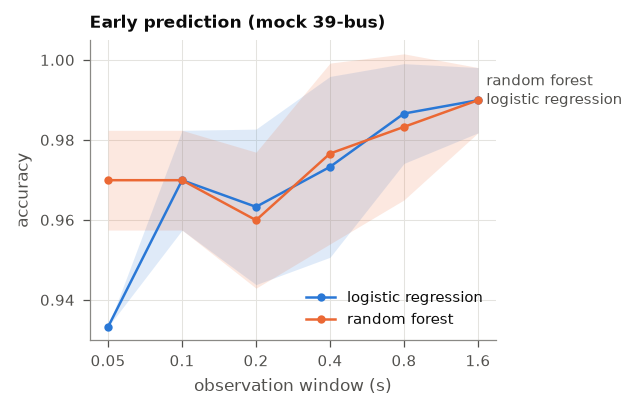

In [7]:
with publication_style():
    fig = plot_early_prediction(curve, title="Early prediction (mock 39-bus)")
    save_figure(fig, FIGURES / "05_early_prediction.pdf")
plt.show()